In [ ]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split , GridSearchCV 
from sklearn.metrics import accuracy_score, f1_score


import warnings
warnings.filterwarnings('ignore')

## Part 1: Data Understanding:

In [25]:
df = pd.read_csv("Dry_Bean_Dataset.csv")

In [26]:
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  object 
dtypes: float64(1

In [28]:
df.Class.value_counts()

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

In [29]:
df.shape

(13611, 17)

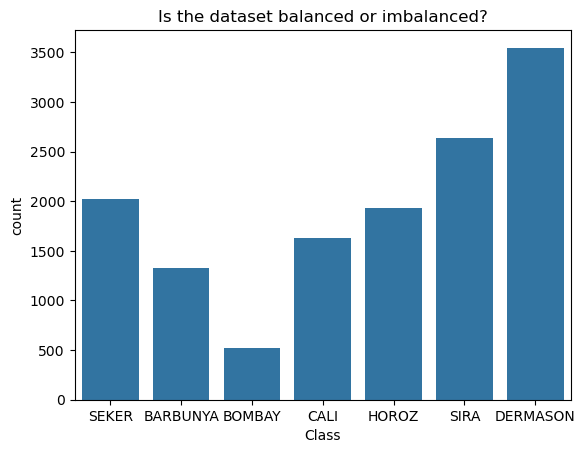

In [30]:
sns.countplot(data = df , x = 'Class')
plt.title("Is the dataset balanced or imbalanced?")
plt.show()

In [31]:
#Is the dataset balanced or imbalanced?
#The dataset is imbalanced. The bar chart shows that the seven classes do not have similar sample counts:
#DERMASON is the largest class with roughly 3546 samples.
#SIRA follows with roughly 2636 samples.
#SEKER and HOROZ each have roughly 2027 , 1928 samples.
#CALI has roughly 1630 samples and BARBUNYA roughly 1322.
#BOMBAY is the smallest class with only 522 samples.
#The largest class (DERMASON) is about 7 times larger than the smallest class (BOMBAY). In a balanced dataset, all bars would be roughly the same height, which is clearly not the case here.

## Part 2: Data Exploration & Preprocessing:

In [32]:
df.isnull().sum()

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

In [33]:
df.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860154,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


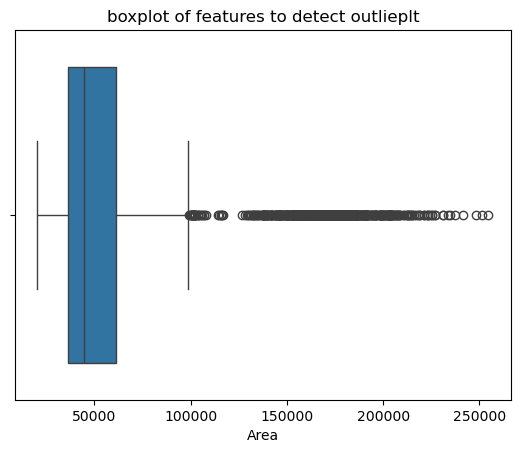

In [34]:
sns.boxplot(data = df,x = 'Area')
plt.title("boxplot of features to detect outlieplt")
plt.show()

In [35]:
Q1 = df.Area.quantile(0.25)
Q3 = df.Area.quantile(0.75)
print(f'Q1 --> {Q1}')
print(f'Q3 --> {Q3}')
print("-"*15)
IQR = Q3 - Q1
print(f'IQR --> {IQR}')
print("-"*15)
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR
print(f'lower --> {lower}')
print(f'upper --> {upper}')


Q1 --> 36328.0
Q3 --> 61332.0
---------------
IQR --> 25004.0
---------------
lower --> -1178.0
upper --> 98838.0


In [36]:
outliers = df[(df.Area<lower)|(df.Area>upper)]

In [37]:
outliers

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
3344,100846,1297.770,469.285655,274.423910,1.710076,0.811200,102015,358.331013,0.792036,0.988541,0.752442,0.763567,0.004653,0.000976,0.583034,0.997033,BARBUNYA
3345,102015,1271.970,456.791895,286.894421,1.592195,0.778162,103901,360.401904,0.804973,0.981848,0.792356,0.788985,0.004478,0.001070,0.622497,0.991137,BARBUNYA
3346,102379,1296.377,456.722068,286.557574,1.593823,0.778679,104111,361.044307,0.739412,0.983364,0.765523,0.790512,0.004461,0.001075,0.624909,0.995995,BARBUNYA
3347,105542,1265.623,466.135980,288.999342,1.612931,0.784610,107112,366.579116,0.747888,0.985342,0.827993,0.786421,0.004417,0.001042,0.618458,0.997530,BARBUNYA
3348,115967,1359.763,449.454969,331.305270,1.356619,0.675755,118497,384.257427,0.742712,0.978649,0.788166,0.854941,0.003876,0.001277,0.730924,0.991585,BARBUNYA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5496,106806,1263.899,494.727002,276.176469,1.791344,0.829679,108109,368.767709,0.705451,0.987947,0.840196,0.745396,0.004632,0.000882,0.555616,0.995299,CALI
5497,107911,1298.822,498.597779,279.350337,1.784848,0.828309,110337,370.670410,0.731898,0.978013,0.803852,0.743426,0.004620,0.000871,0.552682,0.986453,CALI
5498,114858,1300.819,512.736642,287.561719,1.783049,0.827926,115826,382.415674,0.688713,0.991643,0.852977,0.745833,0.004464,0.000852,0.556266,0.991850,CALI
5499,115608,1298.623,500.298310,296.898826,1.685080,0.804876,117222,383.662192,0.779650,0.986231,0.861453,0.766867,0.004328,0.000923,0.588085,0.990970,CALI


In [42]:
df= df[(df.Area>=lower)&(df.Area<=upper)]

In [43]:
df

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653247,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON


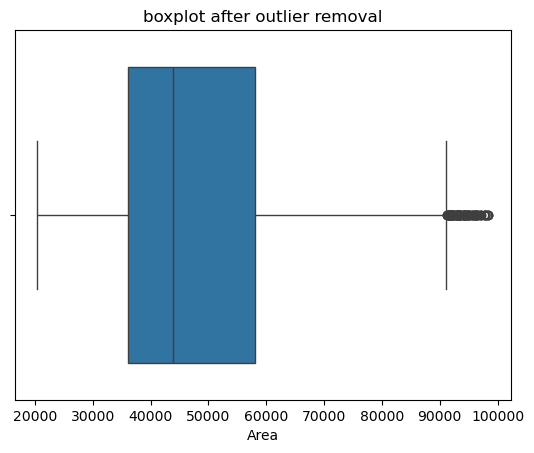

In [44]:
sns.boxplot(data = df,x = 'Area')
plt.title("boxplot after outlier removal")
plt.show()

## Part 3: Train–Test Strategy:

In [46]:
x = df.drop(columns= ['Class'])
y = df.Class

In [52]:
# Stratified split
x_train_s,x_test_s,y_train_s,y_test_s= train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [53]:
# Non-stratified split
x_train,x_test,y_train,y_test= train_test_split(x,y,test_size=0.2,random_state=42)

In [55]:
dist = pd.DataFrame({
    'Original':        y.value_counts(normalize=True),
    'Train (Strat.)':  y_train_s.value_counts(normalize=True),
    'Test (Strat.)':   y_test_s.value_counts(normalize=True),
    'Train (NonStrat.)': y_train.value_counts(normalize=True),
    'Test (NonStrat.)':  y_test.value_counts(normalize=True),
}).round(4)

In [56]:
print(dist)

          Original  Train (Strat.)  Test (Strat.)  Train (NonStrat.)  \
Class                                                                  
DERMASON    0.2715          0.2715         0.2714             0.2742   
SIRA        0.2018          0.2019         0.2018             0.1996   
SEKER       0.1552          0.1552         0.1551             0.1551   
HOROZ       0.1476          0.1476         0.1478             0.1480   
CALI        0.1230          0.1230         0.1229             0.1231   
BARBUNYA    0.1008          0.1008         0.1011             0.1001   

          Test (NonStrat.)  
Class                       
DERMASON            0.2607  
SIRA                0.2109  
SEKER               0.1558  
HOROZ               0.1462  
CALI                0.1225  
BARBUNYA            0.1038  


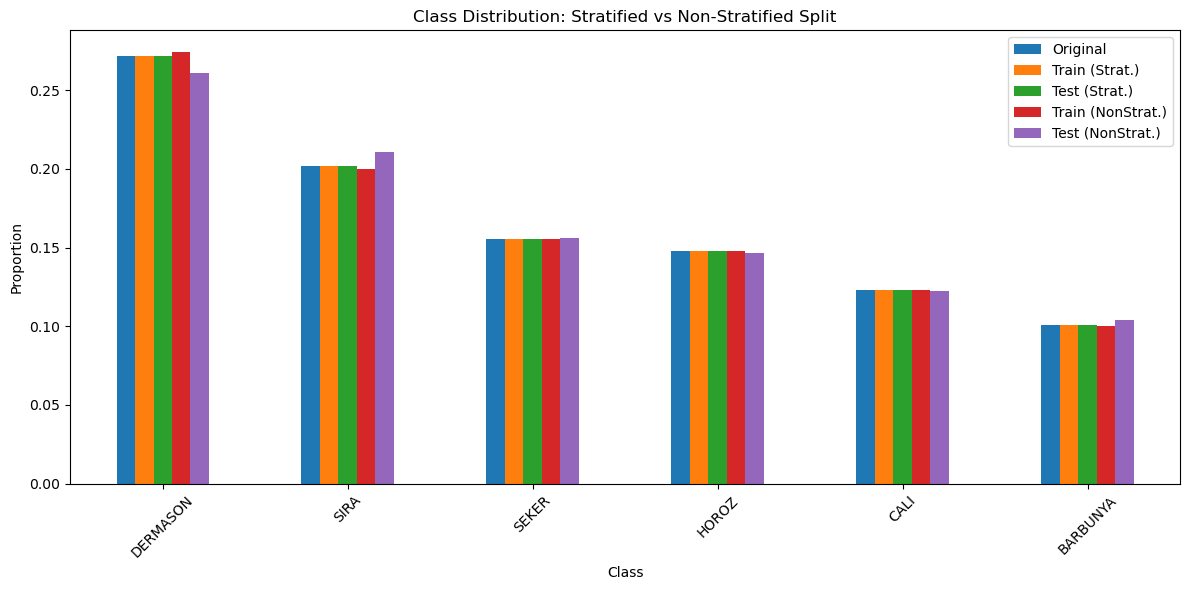

In [57]:
dist.plot(kind='bar', figsize=(12, 6))
plt.title('Class Distribution: Stratified vs Non-Stratified Split')
plt.ylabel('Proportion')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
results = []
for test_size in [0.3, 0.2]:
    for strat in [True, False]:
        x_tr, x_te, y_tr, y_te = train_test_split(
            x, y, test_size=test_size, random_state=42,
            stratify=y if strat else None
        )
        scaler = StandardScaler()
        x_tr_sc = scaler.fit_transform(x_tr)
        x_te_sc = scaler.transform(x_te)

        knn = KNeighborsClassifier(n_neighbors=5)
        knn.fit(x_tr_sc, y_tr)
        y_pred = knn.predict(x_te_sc)

        results.append({
            'Split': f'{int((1-test_size)*100)}/{int(test_size*100)}',
            'Stratified': strat,
            'Accuracy': accuracy_score(y_te, y_pred),
            'F1 (weighted)': f1_score(y_te, y_pred, average='weighted')
        })

results_df = pd.DataFrame(results).round(4)
print(results_df)

   Split  Stratified  Accuracy  F1 (weighted)
0  70/30        True    0.9176         0.9176
1  70/30       False    0.9199         0.9200
2  80/20        True    0.9204         0.9205
3  80/20       False    0.9215         0.9216


## Part 4: KNN Implementation & Hyperparameter Tuning:

In [62]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
x_train_sc = scaler.fit_transform(x_train)
x_test_sc = scaler.transform(x_test)

In [63]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_sc, y_train)
y_pred = knn.predict(x_te_sc)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1-score (weighted):", f1_score(y_test, y_pred, average='weighted'))

Accuracy: 0.19065849923430322
F1-score (weighted): 0.19059903887954777


Best k: 12 | Accuracy: 0.9207503828483921


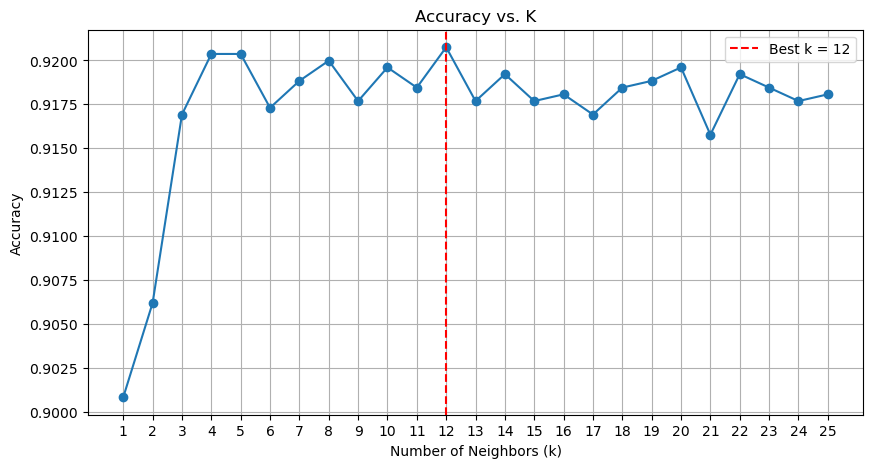

In [64]:
k_values = range(1, 26)
acc = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(x_train_sc, y_train)
    acc.append(accuracy_score(y_test, knn.predict(x_test_sc)))

best_k = k_values[np.argmax(acc)]
print("Best k:", best_k, "| Accuracy:", max(acc))

plt.figure(figsize=(10, 5))
plt.plot(k_values, acc, marker='o')
plt.axvline(best_k, color='red', linestyle='--', label=f'Best k = {best_k}')
plt.title('Accuracy vs. K')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Accuracy')
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()

In [66]:
for metric in ['euclidean', 'manhattan']:
    knn = KNeighborsClassifier(n_neighbors=best_k, metric=metric)
    knn.fit(x_train_sc, y_train)
    y_pred = knn.predict(x_test_sc)
    print(f"{metric:10s} | Accuracy: {accuracy_score(y_test, y_pred):.4f} "
          f"| F1: {f1_score(y_test, y_pred, average='weighted'):.4f}")

euclidean  | Accuracy: 0.9208 | F1: 0.9208
manhattan  | Accuracy: 0.9154 | F1: 0.9154


## Part 5: Confusion Matrix Analysis:

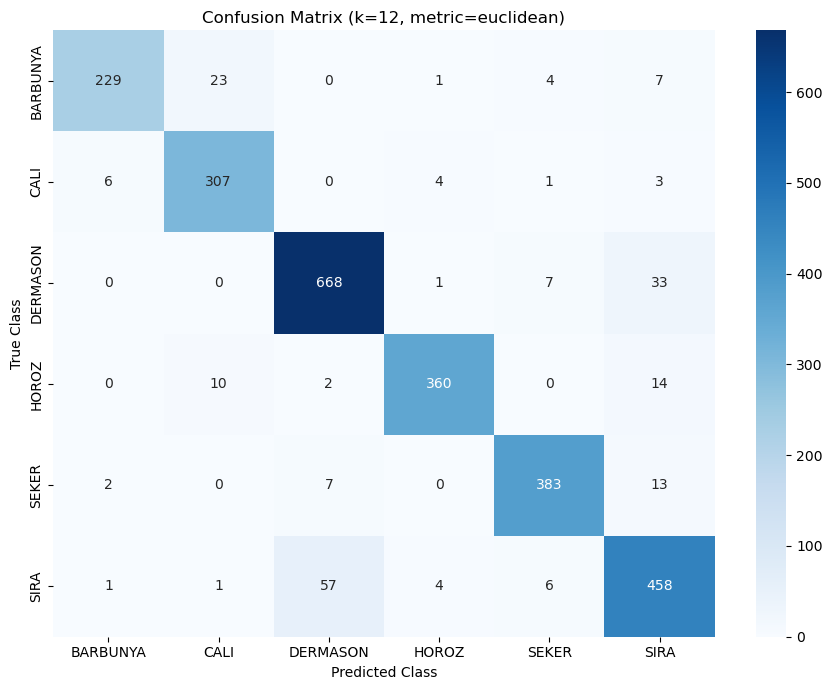

In [67]:
from sklearn.metrics import confusion_matrix, classification_report
best_metric = 'euclidean'
best_model = KNeighborsClassifier(n_neighbors=best_k, metric=best_metric)
best_model.fit(x_train_sc, y_train)
y_pred = best_model.predict(x_test_sc)
labels = best_model.classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.title(f'Confusion Matrix (k={best_k}, metric={best_metric})')
plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.tight_layout()
plt.show()

In [68]:
errors = []
for i, true_label in enumerate(labels):
    for j, pred_label in enumerate(labels):
        if i != j and cm[i, j] > 0:
            errors.append((true_label, pred_label, cm[i, j]))
errors_df = pd.DataFrame(errors, columns=['True', 'Predicted', 'Count'])
print(errors_df.sort_values('Count', ascending=False).head(5))
print(classification_report(y_test, y_pred))

        True Predicted  Count
19      SIRA  DERMASON     57
10  DERMASON      SIRA     33
0   BARBUNYA      CALI     23
13     HOROZ      SIRA     14
16     SEKER      SIRA     13
              precision    recall  f1-score   support

    BARBUNYA       0.96      0.87      0.91       264
        CALI       0.90      0.96      0.93       321
    DERMASON       0.91      0.94      0.93       709
       HOROZ       0.97      0.93      0.95       386
       SEKER       0.96      0.95      0.95       405
        SIRA       0.87      0.87      0.87       527

    accuracy                           0.92      2612
   macro avg       0.93      0.92      0.92      2612
weighted avg       0.92      0.92      0.92      2612



## Part 6: How KNN Works Fast (Optional)

In [69]:
import time
from scipy import stats
A = x_train_sc            
B = x_test_sc[:200]       

In [70]:
def dist_two_loops(B, A):
    dists = np.zeros((B.shape[0], A.shape[0]))
    for i in range(B.shape[0]):
        for j in range(A.shape[0]):
            dists[i, j] = np.sqrt(np.sum((B[i] - A[j]) ** 2))
    return dists

In [71]:
def dist_one_loop(B, A):
    dists = np.zeros((B.shape[0], A.shape[0]))
    for i in range(B.shape[0]):
        dists[i, :] = np.sqrt(np.sum((A - B[i]) ** 2, axis=1))
    return dists

In [72]:
def dist_no_loops(B, A):
    B_sq = np.sum(B ** 2, axis=1).reshape(-1, 1)  
    A_sq = np.sum(A ** 2, axis=1).reshape(1, -1)   
    cross = B @ A.T                                 
    return np.sqrt(np.maximum(B_sq + A_sq - 2 * cross, 0))

In [73]:
for name, func in [('Two loops', dist_two_loops),
                   ('One loop', dist_one_loop),
                   ('No loops', dist_no_loops)]:
    start = time.time()
    d = func(B, A)
    print(f"{name:10s}: {time.time() - start:.4f} seconds")
print(np.allclose(dist_two_loops(B[:20], A), dist_no_loops(B[:20], A)))
print(np.allclose(dist_one_loop(B, A), dist_no_loops(B, A)))

Two loops : 20.9436 seconds
One loop  : 0.2425 seconds
No loops  : 0.0522 seconds
True
True


In [75]:
def knn_predict(X_train, y_train, X_test, k=5):
    dists = dist_no_loops(X_test, X_train)
    nearest = np.argsort(dists, axis=1)[:, :k]
    classes, y_idx = np.unique(np.asarray(y_train), return_inverse=True)
    neighbor_idx = y_idx[nearest]                 
    votes = np.apply_along_axis(np.bincount, 1, neighbor_idx,
                                minlength=len(classes))
    preds = classes[np.argmax(votes, axis=1)]
    return preds
y_pred_fast = knn_predict(x_train_sc, y_train, x_test_sc, k=best_k)
print("Accuracy:", accuracy_score(y_test, y_pred_fast))

Accuracy: 0.9207503828483921
